<a href="https://colab.research.google.com/github/taehi5/ESAA_YB_1/blob/main/final_submission_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 와인 품질 분류 · 최종 제출 코드
**ExtraTrees 0.9 + CatBoost 0.1 확률 앙상블 (원본 변수 12개) → Public 0.711**

| 과제 조건 | 이 노트북에서 |
|---|---|
| 데이터 전처리 | 2장: `type` 인코딩, 변수 분리 (+ 실험한 전처리와 제외 이유) |
| 시각화 | 1장 EDA 5종 + 3·4장 모델 비교 · 혼동행렬 · 변수 중요도 |
| 분류 모델 3가지 이상 | 3장: RandomForest · ExtraTrees · LightGBM · CatBoost **4가지** 비교 |
| 리더보드 점수 | Public **0.711** |

| 항목 | 내용 |
|---|---|
| 최종 모델 | ExtraTrees(트리 1000개) + CatBoost(07·08번 튜닝 파라미터) |
| 앙상블 | 두 모델의 예측 확률을 ET 0.9 : Cat 0.1로 가중 평균 |
| 검증 | StratifiedKFold 5-fold, Accuracy |

**최종 구성으로 고른 이유**
파생변수, 이상치 클리핑, 변수 선택, 불균형 처리(가중치·오버샘플링·SMOTE), 튜닝, 다른 모델(KNN·SVM·TabPFN), 스태킹, 후처리까지 시도했지만 리더보드는 모두 0.699 ~ 0.711 안에 머물렀습니다. 그래서 **가장 단순하면서 점수가 가장 높은 구성**을 최종으로 선택했습니다. (실험 노트북 10 ~ 24번 참고)

## 1. 데이터 불러오기 · EDA

In [1]:
# 필요한 패키지가 없을 때만 설치 (Colab 등에서 처음 실행할 때)
try:
    import lightgbm, catboost
except ImportError:
    get_ipython().run_line_magic('pip', 'install -q lightgbm catboost')

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#경고 메시지 숨기기
import warnings
warnings.filterwarnings(action='ignore')

# Colab이면 구글 드라이브, 로컬이면 로컬 경로 사용
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/ESAA/ESAA미니프로젝트2/'
else:
    DATA_DIR = 'C:/Users/taehe/OneDrive/문서/대학교/dataset/와인품질분류/data/'

train = pd.read_csv(DATA_DIR + 'train.csv')
test = pd.read_csv(DATA_DIR + 'test.csv')
submission = pd.read_csv(DATA_DIR + 'sample_submission.csv')
train.shape, test.shape

Mounted at /content/drive


((5497, 14), (1000, 13))

In [3]:
# 5,497행, 결측치 없음, type만 문자형
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5497 entries, 0 to 5496
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 5497 non-null   int64  
 1   quality               5497 non-null   int64  
 2   fixed acidity         5497 non-null   float64
 3   volatile acidity      5497 non-null   float64
 4   citric acid           5497 non-null   float64
 5   residual sugar        5497 non-null   float64
 6   chlorides             5497 non-null   float64
 7   free sulfur dioxide   5497 non-null   float64
 8   total sulfur dioxide  5497 non-null   float64
 9   density               5497 non-null   float64
 10  pH                    5497 non-null   float64
 11  sulphates             5497 non-null   float64
 12  alcohol               5497 non-null   float64
 13  type                  5497 non-null   object 
dtypes: float64(11), int64(2), object(1)
memory usage: 601.4+ KB


### (1) 품질 등급 분포
5·6등급이 대부분이고 3·9등급은 매우 적은 **불균형** 데이터입니다.

quality
3      26
4     186
5    1788
6    2416
7     924
8     152
9       5
Name: count, dtype: int64


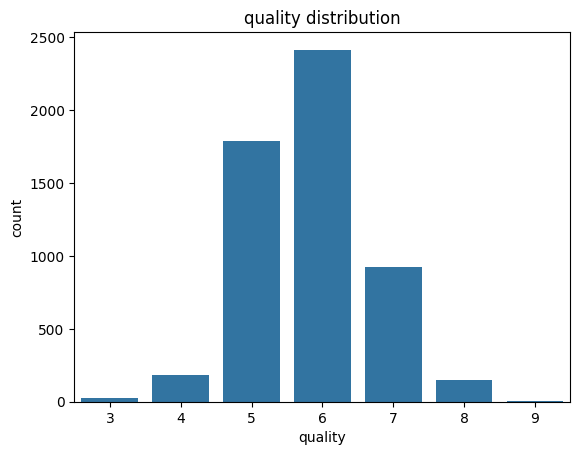

In [4]:
print(train['quality'].value_counts().sort_index())
sns.countplot(x='quality', data=train)
plt.title('quality distribution')
plt.show()

### (2) 와인 종류별 품질 분포
화이트 와인이 레드보다 약 3배 많고, 두 종류 모두 5·6등급 중심입니다.

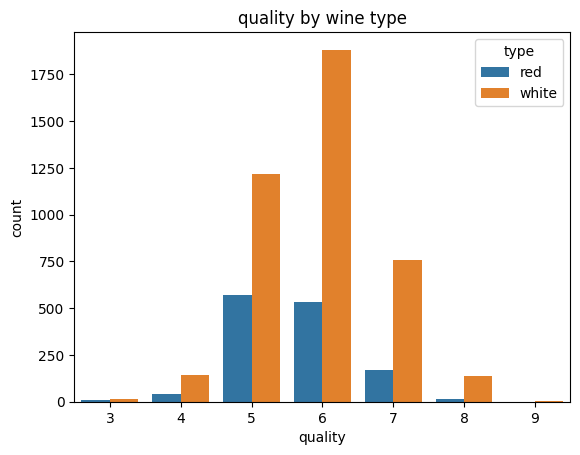

In [5]:
sns.countplot(x='quality', hue='type', data=train)
plt.title('quality by wine type')
plt.show()

### (3) 변수 간 상관관계
quality와는 `alcohol`이 가장 강한 양의 상관, `density`·`volatile acidity`가 음의 상관을 보입니다.

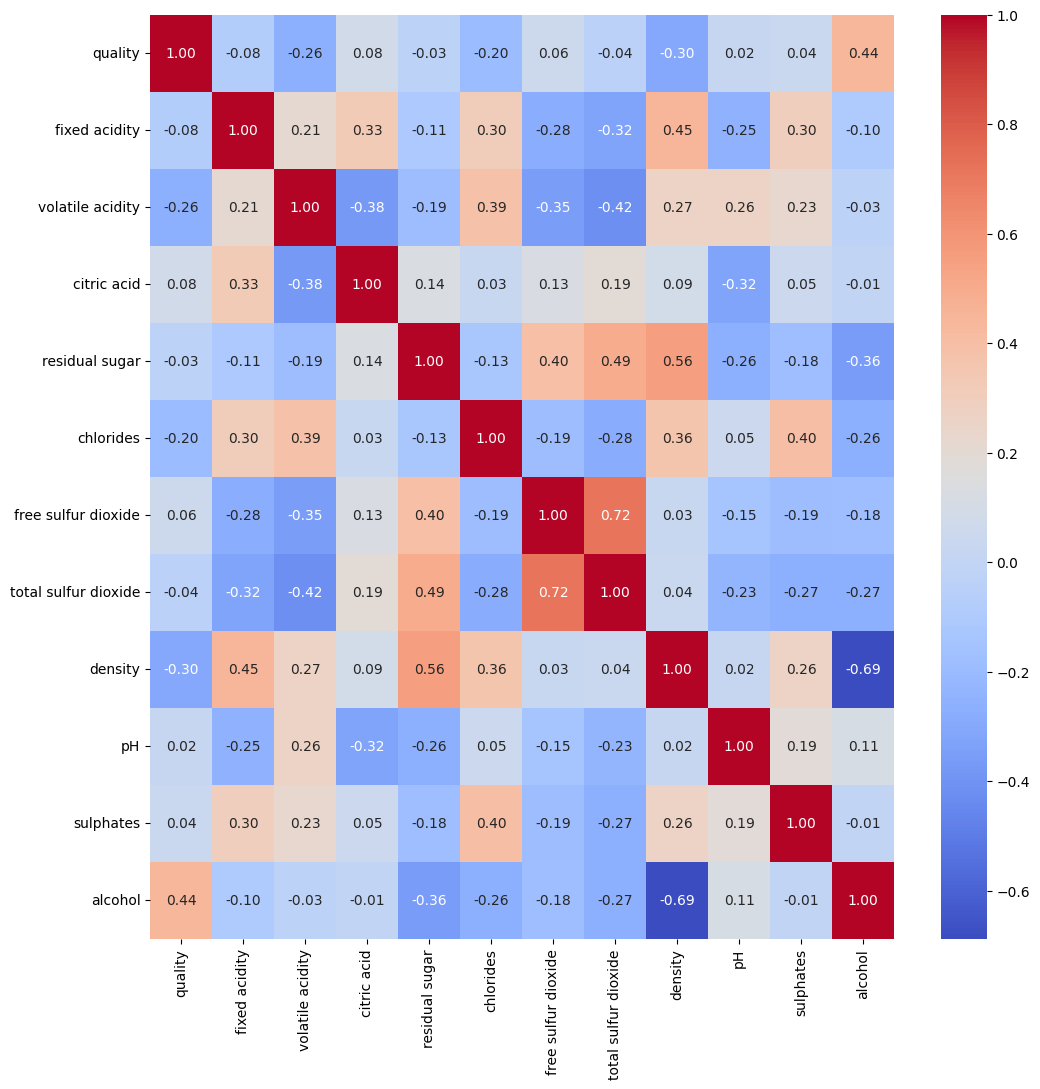

In [6]:
plt.figure(figsize=(12,12))
sns.heatmap(data=train.drop(columns='index').corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

### (4) 변수별 분포
`residual sugar`, `chlorides`, 이산화황 변수처럼 오른쪽으로 긴 꼬리를 가진 변수가 많습니다.

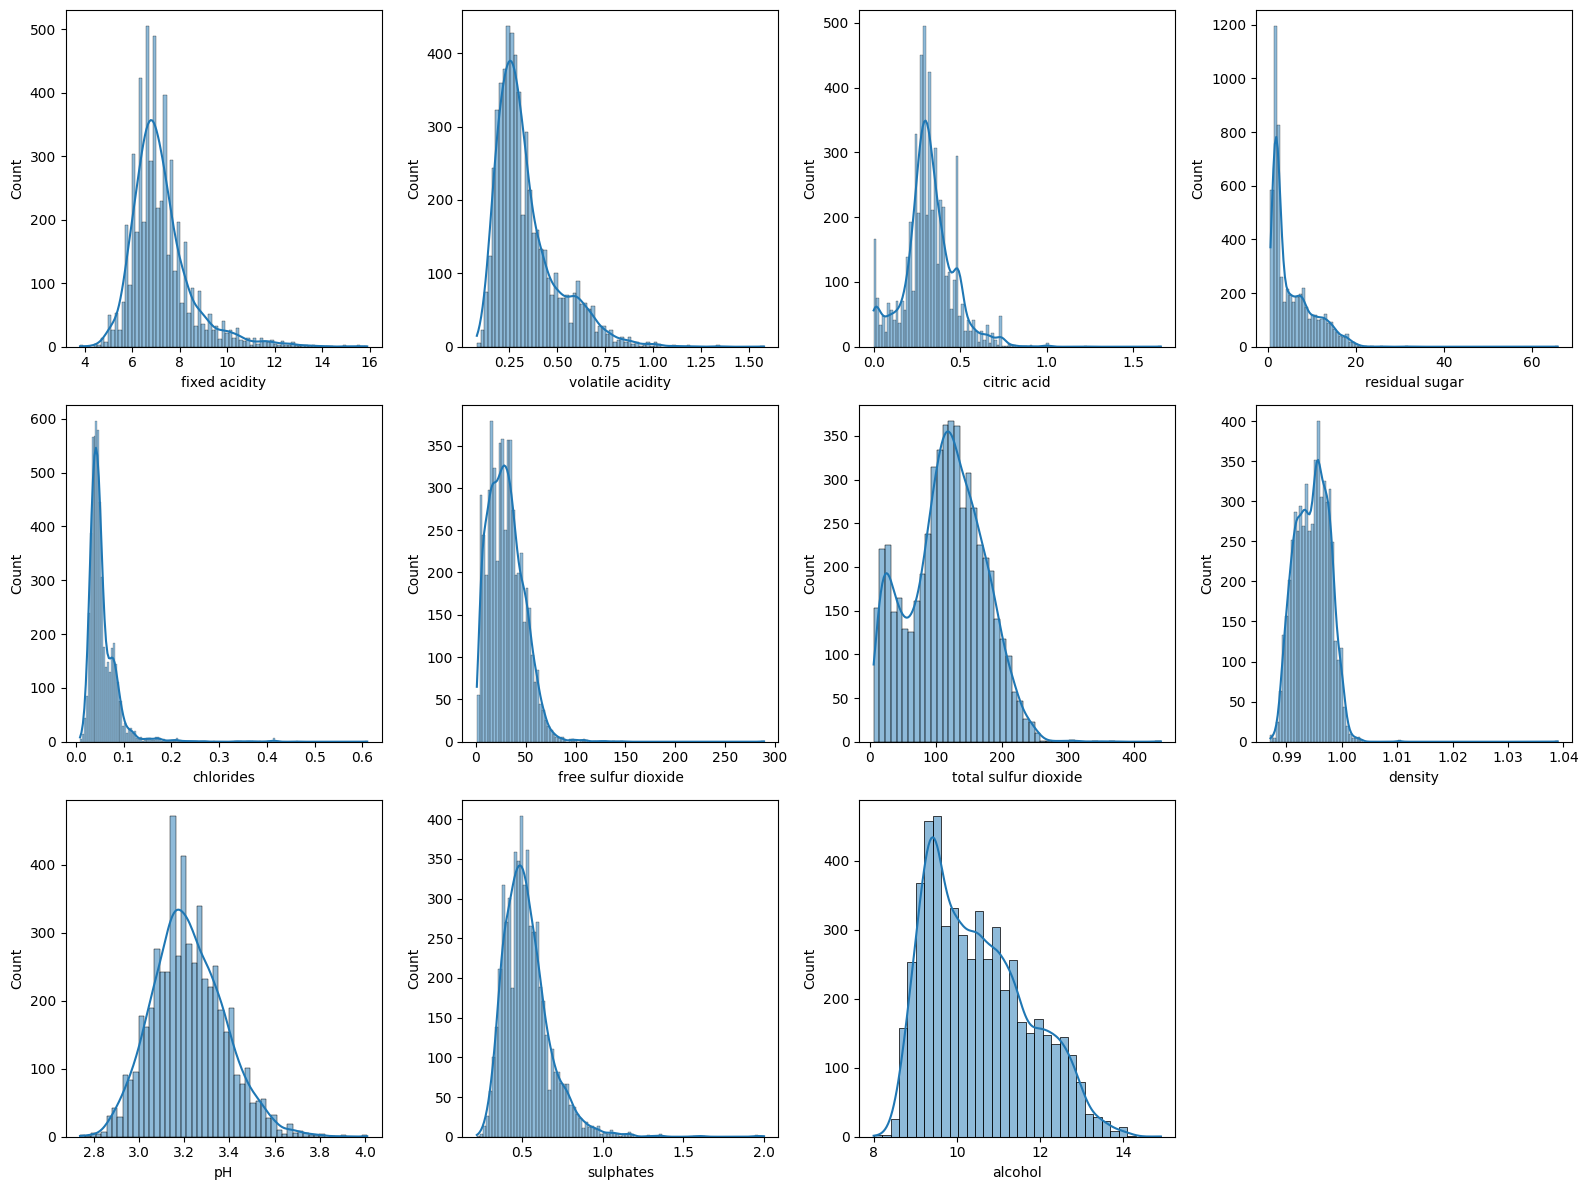

In [7]:
num_cols = train.columns.drop(['index', 'quality', 'type'])
plt.figure(figsize=(16,12))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 4, i)
    sns.histplot(train[col], kde=True)
plt.tight_layout()
plt.show()

### (5) 품질 등급별 주요 변수
상관이 큰 세 변수를 등급별로 비교합니다. 등급이 높을수록 `alcohol`은 높고 `density`·`volatile acidity`는 낮아지는 경향이 있지만, 등급 간 겹치는 구간도 넓어 분류가 쉽지 않은 데이터입니다.

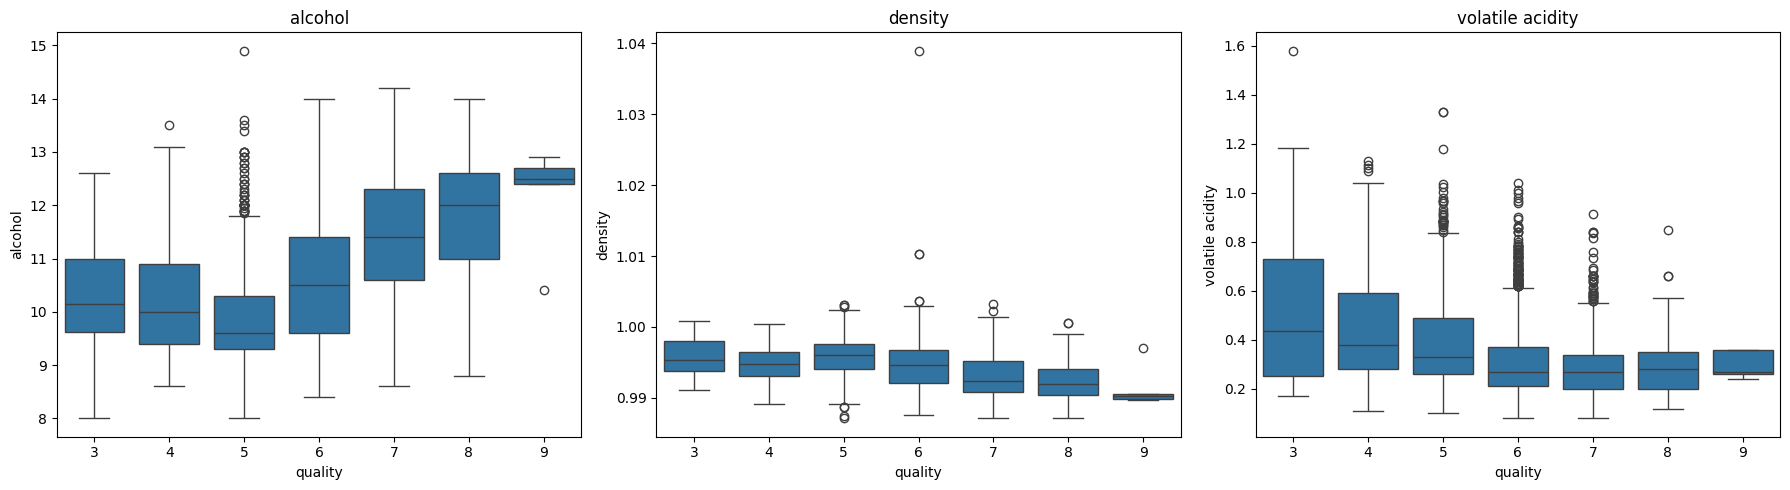

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, col in zip(axes, ['alcohol', 'density', 'volatile acidity']):
    sns.boxplot(x='quality', y=col, data=train, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 2. 전처리
- `type`(red/white)을 0/1로 변환
- `index`는 예측에 의미 없는 번호라 제거, `quality`는 정답(y)으로 분리

**실험했지만 제외한 전처리** (5-fold CV, ExtraTrees 기준 0.6802 대비)

| 전처리 | 결과 | 제외 이유 |
|---|---|---|
| 파생변수 (free_sulfur_ratio, bound_sulfur, alcohol_density, sugar_alcohol 등) | 0.6740 ~ 0.6849 | CV가 소폭 올라도 리더보드에서 재현되지 않음 (0.699 ~ 0.709) |
| 이상치 클리핑 (1% · 99%) | 0.6756 | 트리 모델은 극단값 영향을 덜 받아 효과 없음 |
| 변수 선택 (ANOVA 상위 75%) | 0.6687 | 가장 크게 하락 |
| 스케일링 (StandardScaler) | 효과 없음 | 트리 모델은 값의 크기가 아니라 순서로 분할 |
| 불균형 처리 (가중치 · 오버샘플링 · SMOTE) | 하락 | 평가지표가 정확도라 다수 등급(5·6)을 덜 맞히게 됨 |

In [9]:
from sklearn.preprocessing import LabelEncoder

# type(red/white) → 0/1
enc = LabelEncoder()
enc.fit(train['type'])
train['type'] = enc.transform(train['type'])
test['type'] = enc.transform(test['type'])

# 문제(X) / 정답(y) 분리
train_x = train.drop(['index', 'quality'], axis=1)
train_y = train['quality']
test_x = test.drop('index', axis=1)
train_x.shape, train_y.shape, test_x.shape

((5497, 12), (5497,), (1000, 12))

## 3. 분류 모델 비교 (4가지)
| 모델 | 방식 | 설정 |
|---|---|---|
| RandomForest | 배깅 (부트스트랩 + 최적 분할) | 트리 1000개 |
| ExtraTrees | 배깅 (전체 데이터 + 무작위 분할) | 트리 1000개 |
| LightGBM | 부스팅 | 기본값 |
| CatBoost | 부스팅 | 07·08번 튜닝 파라미터 |

네 모델 모두 **같은 5-fold 분할**로 검증 데이터의 예측 확률(OOF)을 구합니다. 같은 분할을 써야 모델끼리 공정하게 비교하고, 확률을 행 단위로 섞을 수 있습니다.

In [10]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

models = {
    'RandomForest': RandomForestClassifier(n_estimators=1000, random_state=42, n_jobs=-1),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=1000, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(random_state=42, n_jobs=-1, verbosity=-1),
    'CatBoost': CatBoostClassifier(iterations=800, learning_rate=0.06018992766242183,
        depth=7, l2_leaf_reg=1.0189247089455022, random_strength=1.4597350182073558,
        random_seed=42, thread_count=-1, verbose=False, allow_writing_files=False),
}

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
classes = np.sort(train_y.unique())  # predict_proba의 열 순서 (3~9)

oof = {}
for name, model in models.items():
    oof[name] = cross_val_predict(model, train_x, train_y, cv=cv, method='predict_proba')
    print(f'{name} CV 정확도:', round(accuracy_score(train_y, classes[oof[name].argmax(1)]), 4))

RandomForest CV 정확도: 0.6693
ExtraTrees CV 정확도: 0.6802
LightGBM CV 정확도: 0.6438
CatBoost CV 정확도: 0.656


### 앙상블 비중 확인
가장 좋은 ExtraTrees에 CatBoost를 섞습니다. `w`는 ExtraTrees 비중입니다 (`w=1`이면 ET만, `w=0`이면 CatBoost만). 최종으로는 **w = 0.9**를 사용합니다.

In [12]:
ens_scores = {}
for w in [0, 0.3, 0.5, 0.7, 0.8, 0.9, 1]:
    prob = w * oof['ExtraTrees'] + (1 - w) * oof['CatBoost']
    ens_scores[w] = accuracy_score(train_y, classes[prob.argmax(1)])

result = pd.Series(ens_scores, name='cv_accuracy')
result.index.name = 'ExtraTrees 비중(w)'
result.round(4)

,cv_accuracy
ExtraTrees 비중(w),
0.0,0.6560
0.3,0.6664
0.5,0.6704
0.7,0.6755
0.8,0.6787
0.9,0.6804
1.0,0.6802


### 모델별 CV 정확도 비교

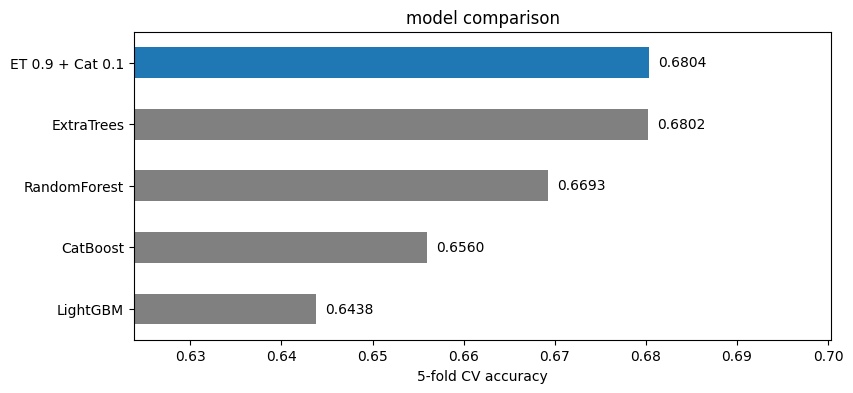

In [13]:
W_ET = 0.9  # ExtraTrees 비중
ens_oof = W_ET * oof['ExtraTrees'] + (1 - W_ET) * oof['CatBoost']

compare = pd.Series({name: accuracy_score(train_y, classes[p.argmax(1)]) for name, p in oof.items()})
compare['ET 0.9 + Cat 0.1'] = accuracy_score(train_y, classes[ens_oof.argmax(1)])
compare = compare.sort_values()

colors = ['tab:blue' if name == 'ET 0.9 + Cat 0.1' else 'gray' for name in compare.index]
plt.figure(figsize=(9,4))
ax = compare.plot.barh(color=colors)
for i, v in enumerate(compare):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center')
plt.xlim(compare.min() - 0.02, compare.max() + 0.02)
plt.xlabel('5-fold CV accuracy')
plt.title('model comparison')
plt.show()

### 최종 앙상블의 혼동행렬 (OOF)
대부분의 오답은 5↔6, 6↔7처럼 **이웃한 등급**끼리 헷갈린 것입니다. 3·9등급은 학습 데이터가 너무 적어 거의 맞히지 못합니다.

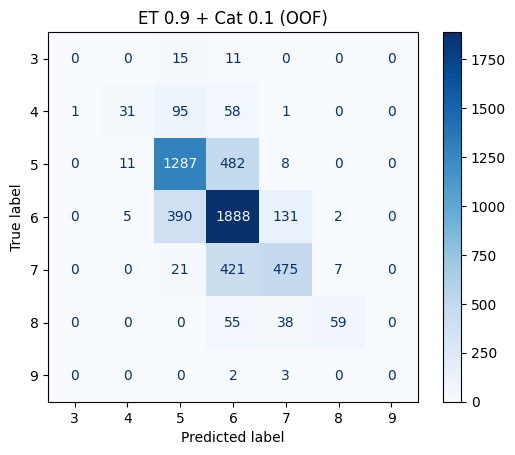

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(train_y, classes[ens_oof.argmax(1)], labels=classes, cmap='Blues')
plt.title('ET 0.9 + Cat 0.1 (OOF)')
plt.show()

## 4. 최종 학습 및 제출 파일 생성
ExtraTrees와 CatBoost를 **전체 train**으로 다시 학습하고, test 예측 확률을 ET 0.9 : Cat 0.1로 섞어 가장 확률이 높은 등급을 고릅니다.

In [15]:
et = models['ExtraTrees'].fit(train_x, train_y)
cat = models['CatBoost'].fit(train_x, train_y)
test_prob = W_ET * et.predict_proba(test_x) + (1 - W_ET) * cat.predict_proba(test_x)

submission['quality'] = classes[test_prob.argmax(1)]
submission.to_csv('final_submission.csv', index=False)
submission['quality'].value_counts().sort_index()

,count
quality,
4,7
5,346
6,512
7,122
8,13


### ExtraTrees 변수 중요도
`alcohol`이 가장 중요하고, `volatile acidity`·`density`가 뒤를 잇습니다. EDA에서 quality와 상관이 가장 컸던 세 변수와 일치합니다. 나머지 변수들도 중요도가 고르게 퍼져 있어, 변수를 제거하면(변수 선택) 오히려 성능이 떨어졌던 결과와도 맞습니다.

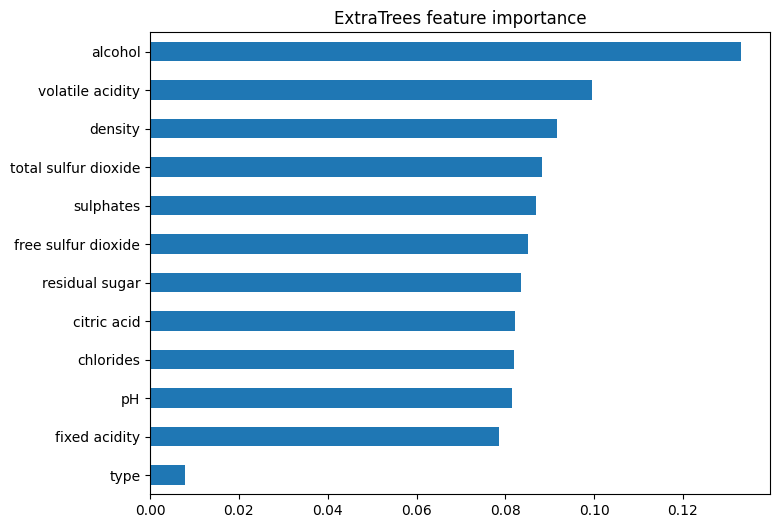

In [16]:
importance = pd.Series(et.feature_importances_, index=train_x.columns).sort_values()
importance.plot.barh(figsize=(8,6))
plt.title('ExtraTrees feature importance')
plt.show()